<a href="https://colab.research.google.com/github/khvanri27/cpp-practice-2026/blob/main/HW5/khvan_rita_640-01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
g++ set to manually installed.
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1

In [4]:
%%writefile main.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

int main() {
    const char* image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    CURL* curl_handle;
    CURLcode res;
    std::vector<uchar> image_data;

    curl_global_init(CURL_GLOBAL_DEFAULT);
    curl_handle = curl_easy_init();

    if(curl_handle) {
        curl_easy_setopt(curl_handle, CURLOPT_URL, image_url);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl_handle, CURLOPT_WRITEDATA, &image_data);
        curl_easy_setopt(curl_handle, CURLOPT_USERAGENT, "libcurl-agent/1.0");

        res = curl_easy_perform(curl_handle);

        if(res != CURLE_OK) {
            std::cerr << "curl_easy_perform() failed: " << curl_easy_strerror(res) << std::endl;
            curl_easy_cleanup(curl_handle);
            curl_global_cleanup();
            return 1;
        }
        curl_easy_cleanup(curl_handle);
    }
    curl_global_cleanup();

    std::cout << "Downloaded " << image_data.size() << " bytes." << std::endl;

    cv::Mat image = cv::imdecode(image_data, cv::IMREAD_COLOR);

    if (image.empty()) {
        std::cerr << "Could not decode image!" << std::endl;
        return 1;
    }

    std::cout << "Image decoded successfully: " << image.cols << "x" << image.rows << std::endl;

    // Сохраняем оригинал, чтобы потом показать его в Python
    cv::imwrite("original_output.jpg", image);

    // Обработка: перевод в оттенки серого
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);

    cv::imwrite("gray_output.jpg", gray);
    std::cout << "Images saved as original_output.jpg and gray_output.jpg" << std::endl;

    return 0;
}

Writing main.cpp


In [5]:
!g++ main.cpp -o main $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./main

Downloaded 91814 bytes.
Image decoded successfully: 512x512
Images saved as original_output.jpg and gray_output.jpg


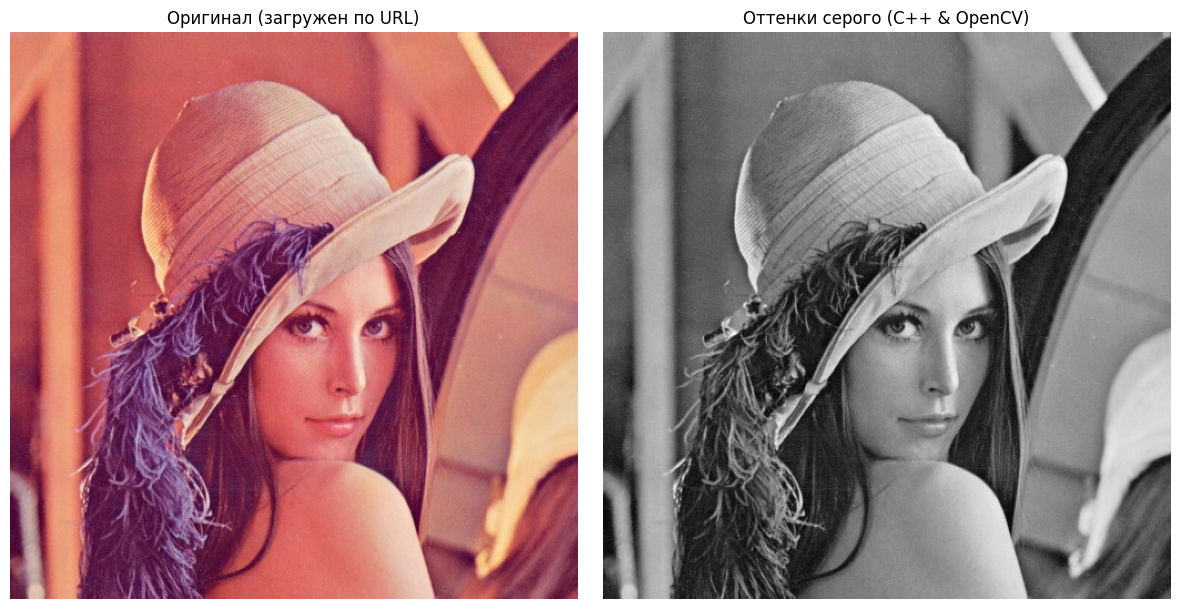

In [6]:
import matplotlib.pyplot as plt
import cv2

# Загружаем оба сохранённых изображения
img_original = cv2.imread('original_output.jpg')
img_gray = cv2.imread('gray_output.jpg', cv2.IMREAD_GRAYSCALE)

if img_original is not None and img_gray is not None:
    # Конвертируем оригинал из BGR (OpenCV) в RGB (Matplotlib)
    img_original_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(img_original_rgb)
    axes[0].set_title('Оригинал (загружен по URL)')
    axes[0].axis('off')

    axes[1].imshow(img_gray, cmap='gray')
    axes[1].set_title('Оттенки серого (C++ & OpenCV)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Не удалось загрузить одно из изображений.")

In [7]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка: URL или локальный файл
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    // Источник: аргумент командной строки, иначе — URL по умолчанию
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "Loading: " << source << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Failed to load image from: " << source << std::endl;
        return 1;
    }
    std::cout << "Image: " << image.cols << "x" << image.rows << std::endl;

    // Каскады
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Cannot load cascades" << std::endl;
        return 1;
    }

    // Подготовка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц — вернёт ВСЕ найденные лица
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(
        gray, faces,
        /*scaleFactor*/  1.05,   // чуть меньше, чем 1.1 — ищем тщательнее (для групповых фото)
        /*minNeighbors*/ 5,
        /*flags*/        0,
        /*minSize*/      cv::Size(20, 20)   // маленькие лица тоже ловим
    );

    std::cout << "Detected faces: " << faces.size() << std::endl;

    // Рисуем рамку + номер для каждого лица
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);

        // Подпись "Face N" над рамкой
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;

        cv::rectangle(image,
                      cv::Point(text_org.x, text_org.y - text_size.height - 2),
                      cv::Point(text_org.x + text_size.width, text_org.y + 2),
                      cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
                    cv::Scalar(0, 0, 0), 2);

        // Глаза ищем только в верхних 60% лица (там они и находятся)
        cv::Mat face_roi_gray  = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }

    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Result saved: faces_detected.jpg" << std::endl;

    if (faces.empty()) {
        std::cerr << "No faces detected. Try another image or lower minNeighbors." << std::endl;
        return 2;
    }
    return 0;
}

Writing detect_faces.cpp


In [8]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17
!./detect_faces

Loading: https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg
Image: 512x512
Detected faces: 1
Result saved: faces_detected.jpg


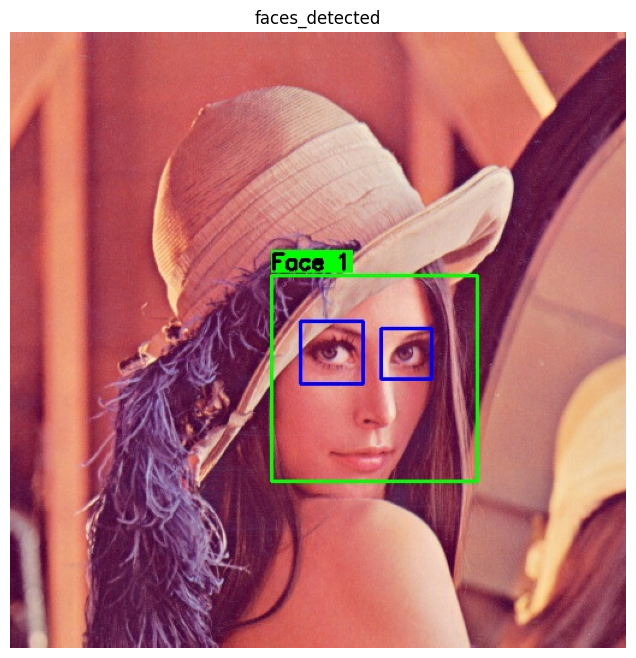

In [9]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

In [11]:
from google.colab import files
uploaded = files.upload()
# После загрузки имя файла появится в выводе, например: "group.jpg"

Saving namjoon.jpeg to namjoon.jpeg


In [12]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

# Замените group.jpeg на имя вашего файла
!./detect_faces namjoon.jpeg

Loading: namjoon.jpeg
Image: 585x769
Detected faces: 3
Result saved: faces_detected.jpg


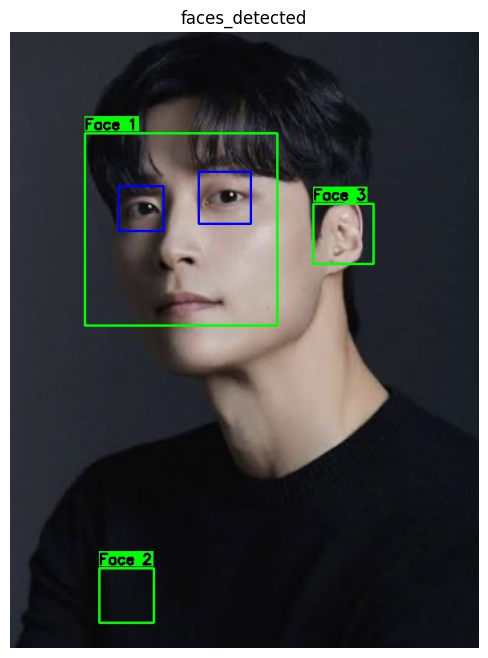

In [13]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')

if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

**На реальном фото изображен 1 человек и 2 глаза, а программа нашла 3 лица и 2 глаза.**

Почему так могло получиться: программа правильно распознала настоящее лицо (Face 1) и глаза. Однако она выдала две ложные находки - Face 2 (на одежде) и Face 3 (на ухе). Это ошибка каскадов Хаара - они ищут контрастные пятна (тени), похожие на черты лица. На черном свитере и волосах тени сложились так, что алгоритм ошибся...

In [14]:
!cat "/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml"

Выходные данные были обрезаны до нескольких последних строк (5000).
          18 2 6 11 -1.</_>
        <_>
          18 2 3 11 2.</_></rects></_>
    <_>
      <rects>
        <_>
          0 2 6 11 -1.</_>
        <_>
          3 2 3 11 2.</_></rects></_>
    <_>
      <rects>
        <_>
          9 12 15 6 -1.</_>
        <_>
          9 14 15 2 3.</_></rects></_>
    <_>
      <rects>
        <_>
          2 2 20 3 -1.</_>
        <_>
          2 3 20 1 3.</_></rects></_>
    <_>
      <rects>
        <_>
          10 6 4 9 -1.</_>
        <_>
          10 6 2 9 2.</_></rects></_>
    <_>
      <rects>
        <_>
          5 6 12 14 -1.</_>
        <_>
          5 6 6 7 2.</_>
        <_>
          11 13 6 7 2.</_></rects></_>
    <_>
      <rects>
        <_>
          9 0 6 9 -1.</_>
        <_>
          11 0 2 9 3.</_></rects></_>
    <_>
      <rects>
        <_>
          7 0 9 6 -1.</_>
        <_>
          10 0 3 6 3.</_></rects></_>
    <_>
      <rects>
        <_>
   

In [15]:
from google.colab import files
uploaded = files.upload()

Saving jungkook.jpeg to jungkook.jpeg


In [16]:
!./detect_faces jungkook.jpeg

Loading: jungkook.jpeg
Image: 613x910
Detected faces: 2
Result saved: faces_detected.jpg


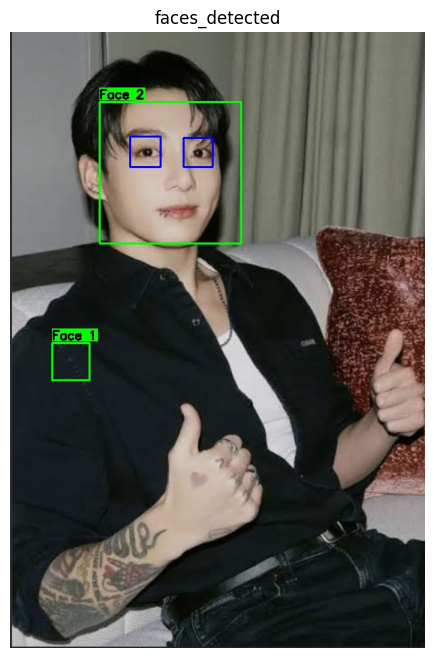

In [17]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')
if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

**На реальном фото изображен 1 человек и 2 глаза, но программа нашла 2 лица и 2 глаза.**

# Почему так получилось:
  Программа верно распознала лицо (Face 2) и глаза на нем. Однако она нашла ложное лицо (Face 1) на рукаве черной одежды. Из-за плохого освещения и складок ткани алгоритм Хаара увидел там контрастный узор, похожий на глаза и нос. Это доказывает, что каскады Хаара часто ошибаются на темных участках одежды и тенях.


In [18]:
!cat "/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml"

Выходные данные были обрезаны до нескольких последних строк (5000).
          18 2 6 11 -1.</_>
        <_>
          18 2 3 11 2.</_></rects></_>
    <_>
      <rects>
        <_>
          0 2 6 11 -1.</_>
        <_>
          3 2 3 11 2.</_></rects></_>
    <_>
      <rects>
        <_>
          9 12 15 6 -1.</_>
        <_>
          9 14 15 2 3.</_></rects></_>
    <_>
      <rects>
        <_>
          2 2 20 3 -1.</_>
        <_>
          2 3 20 1 3.</_></rects></_>
    <_>
      <rects>
        <_>
          10 6 4 9 -1.</_>
        <_>
          10 6 2 9 2.</_></rects></_>
    <_>
      <rects>
        <_>
          5 6 12 14 -1.</_>
        <_>
          5 6 6 7 2.</_>
        <_>
          11 13 6 7 2.</_></rects></_>
    <_>
      <rects>
        <_>
          9 0 6 9 -1.</_>
        <_>
          11 0 2 9 3.</_></rects></_>
    <_>
      <rects>
        <_>
          7 0 9 6 -1.</_>
        <_>
          10 0 3 6 3.</_></rects></_>
    <_>
      <rects>
        <_>
   

In [19]:
from google.colab import files
uploaded = files.upload()

Saving bts.jpeg to bts.jpeg


In [20]:
!./detect_faces bts.jpeg

Loading: bts.jpeg
Image: 1284x1030
Detected faces: 13
Result saved: faces_detected.jpg


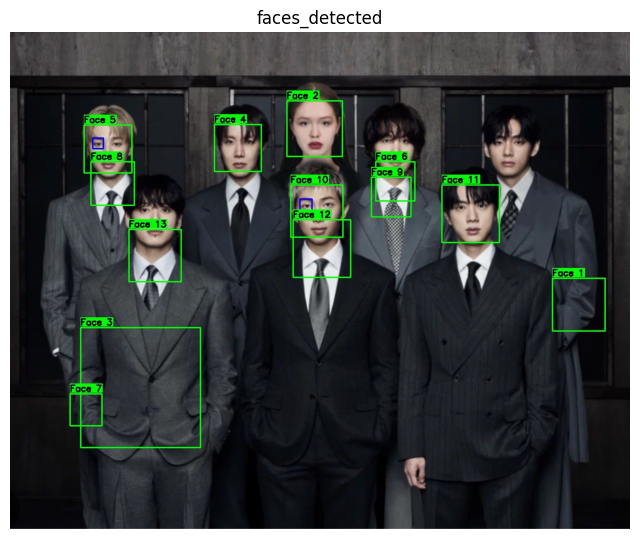

In [22]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread('faces_detected.jpg')
if img is not None:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    plt.title('faces_detected')
    plt.axis('off')
    plt.show()
else:
    print("Не удалось загрузить изображение.")

**На реальном фото изображено 8 человек - полный состав группы BTS и я. Но алгоритм смог распознать лишь 5 человек и 2 глаза, по одному от двух членов группы.**


# Почему так могло получиться:

Программа верно распознала лица (Face 5, 4, 2, 10, 11) и глаза на лицах 5 и 10 (Face 5) (Face 10). Однако она нашла и ложные лица (Face 1 - рукав одежды), (Face 3 - одежда), (Face 6 - подбородок), (Face 7 - край одежды), (Face 8 - нижняя треть лица), (Face 9 - шея), (Face 12, 13 - нижняя треть лица и шея) . Из-за плохого освещения и складок ткани алгоритм Хаара снова увидел там контрастный узор, похожий на черты лица. Это опять же доказывает, что каскады Хаара часто ошибаются на темных участках одежды и тенях.

In [23]:
!cat "/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml"

<?xml version="1.0"?>
<!--
    Stump-based 24x24 discrete(?) adaboost frontal face detector.
    Created by Rainer Lienhart.

////////////////////////////////////////////////////////////////////////////////////////

  IMPORTANT: READ BEFORE DOWNLOADING, COPYING, INSTALLING OR USING.

  By downloading, copying, installing or using the software you agree to this license.
  If you do not agree to this license, do not download, install,
  copy or use the software.


                        Intel License Agreement
                For Open Source Computer Vision Library

 Copyright (C) 2000, Intel Corporation, all rights reserved.
 Third party copyrights are property of their respective owners.

 Redistribution and use in source and binary forms, with or without modification,
 are permitted provided that the following conditions are met:

   * Redistribution's of source code must retain the above copyright notice,
     this list of conditions and the following disclaimer.

   * Redistributio